# **EDKP 616: Individual Reading** #

## **Section 2 : Segment Coordinate Systems and Joint Kinematics** ##


### **1. Joint angle basics** ###

A joint angle describes how one segment is oriented relative to the next; for example, the shank relative to the thigh. In 3D, this takes three rotations, not only one ([Grood & Suntay, 1983](https://doi.org/10.1115/1.3138397)). When coming from 2D gait analysis, in the sagittal plane, one angle is enough and angles simply add up. In 3D, the three angles are linked; their values depend on the axes, the order of the rotations, and the signs that were chosen. Clinicians need three named motions: flexion–extension, adduction–abduction, and internal–external rotation, so a joint-angle method is only useful if its numbers carry those names ([Wu et al., 2002](https://doi.org/10.1016/S0021-9290(01)00222-6)). To be able to compare results from different labs, the International Society of Biomechanics (ISB) proposed a standard built on the Grood and Suntay system ([Wu et al., 2002](https://doi.org/10.1016/S0021-9290(01)00222-6)). The reason these choices matter comes from one property of 3D rotations: their order cannot be swapped.

#### Rotations do not commute ####

Each turn about one axis is a 3 × 3 matrix. Doing two turns in a row means multiplying two matrices.

$$R_x(\theta)=\begin{bmatrix}1&0&0\\0&\cos\theta&-\sin\theta\\0&\sin\theta&\cos\theta\end{bmatrix},\quad R_y(\theta)=\begin{bmatrix}\cos\theta&0&\sin\theta\\0&1&0\\-\sin\theta&0&\cos\theta\end{bmatrix},\quad R_z(\theta)=\begin{bmatrix}\cos\theta&-\sin\theta&0\\\sin\theta&\cos\theta&0\\0&0&1\end{bmatrix}$$

Those multiplications depend on the order: turning about *x* and then *y* is not the same as turning about *y* and then *x*.

$$R_y(90^\circ)\,R_x(90^\circ)\;\neq\;R_x(90^\circ)\,R_y(90^\circ)$$

For example, in the demo below, the point (0, 0, 1) on the *z* axis is given two 90° turns about the fixed lab axes. In one order it ends at (0, −1, 0), in the other order at (1, 0, 0). That means that three angles describe an orientation only if we also state about which axes and in which order they are applied. The same orientation gives different angle triplets in different sequences ([Cole et al., 1993](https://doi.org/10.1115/1.2895496); [Woltring, 1994](https://doi.org/10.1016/0021-9290(94)90191-0)). The order matters the most when one rotation is large (such as 60° of knee flexion) and the others are small. For very small angles, the order matters less.

The demo below shows the problem with two turns.


In [31]:
import numpy as np
import utils.joint_functions as jf

In [32]:
turn_x, turn_y = jf.rotation_matrix('X', 90), jf.rotation_matrix('Y', 90)
print('x first, then y:', (turn_y @ turn_x @ [0, 0, 1]).round(1) + 0)
print('y first, then x:', (turn_x @ turn_y @ [0, 0, 1]).round(1) + 0)

x first, then y: [ 0. -1.  0.]
y first, then x: [1. 0. 0.]


### **2. Euler and Cardan angles** ###

Both Euler and Cardan angles describe an orientation as three successive turns in a fixed order; each turn is about an axis of the body after the previous turn, which gives the matrix product below.

$$R = R_x(a)\,R_y(b)\,R_z(c)=\begin{bmatrix}\cos b\cos c & -\cos b\sin c & \sin b\\ \sin a\sin b\cos c+\cos a\sin c & -\sin a\sin b\sin c+\cos a\cos c & -\sin a\cos b\\ -\cos a\sin b\cos c+\sin a\sin c & \cos a\sin b\sin c+\sin a\cos c & \cos a\cos b\end{bmatrix}$$

There are two families: proper Euler angles repeat an axis (e.g., Z-X-Z), while Cardan angles use three different axes (e.g., X-Y-Z). In gait analysis, joint angles are Cardan angles, even though they are often called Euler angles ([Ramakrishnan & Kadaba, 1991](https://doi.org/10.1016/0021-9290(91)90175-M)). There are six Cardan sequences (XYZ, XZY, YXZ, YZX, ZXY, ZYX), but this notebook only uses three of them: XYZ, ZXY, and YXZ. The numbers depend on the sequence: the same orientation gives different triplets, as can be seen in the demo below. To get the angles back from the matrix, the middle angle is retrieved with arcsin (limited to ±90°) and the other two with atan2, where $R_{ij}$ is the element in row $i$ and column $j$:

$$b=\arcsin(R_{13}),\qquad a=\operatorname{atan2}(-R_{23},\,R_{33}),\qquad c=\operatorname{atan2}(-R_{12},\,R_{11})$$

The other five sequences follow the same pattern. For a joint, the usual sequence is: flexion first, long-axis rotation last, and adduction in between. This is what the Joint Coordinate System does ([Cole et al., 1993](https://doi.org/10.1115/1.2895496); [Wu et al., 2002](https://doi.org/10.1016/S0021-9290(01)00222-6)). The demo below does two things for each sequence: it writes one knee-like orientation as three angles, and it checks that the code can go from angles to a matrix and back.

In [33]:
# one knee-like orientation (flexion, adduction, rotation)
knee_like = jf.cardan_matrix(np.array([-60, 5, -10]), 'XYZ')
tests = np.random.default_rng(1).uniform(-80, 80, (1000, 3))
for sequence in ['XYZ', 'ZXY', 'YXZ']:
    back = jf.cardan_angles(jf.cardan_matrix(tests, sequence), sequence)
    print(sequence, jf.cardan_angles(knee_like, sequence).round(1),
          'round trip error: {:.0e}°'.format(np.abs(back - tests).max()))

XYZ [[-60.   5. -10.]] round trip error: 2e-14°
ZXY [[-19.8 -59.4 -12.2]] round trip error: 2e-14°
YXZ [[  9.9 -59.6 -18.6]] round trip error: 2e-14°


#### Different numbers for the same orientation ####

The first result: one knee-like orientation (60° flexion, 5° adduction, 10° external rotation) written in three sequences. XYZ gives (−60.0, 5.0, −10.0), ZXY gives (−19.8, −59.4, −12.2), and YXZ gives (9.9, −59.6, −18.6). The minus signs in XYZ come from the sign convention explained in Section 3. Although they are different numbers, none of the three is wrong. They are different descriptions of the same orientation, written with the same lab axes (*x* right, *y* forward, *z* up) but in a different order. Only XYZ turns about the flexion axis (*x*) first; therefore, the large rotation is a clean first angle. In ZXY and YXZ, the flexion axis is the middle axis: the flexion shows up as about −59° in the middle slot, and the other two angles change because the 5° of adduction and 10° of rotation are now combined with the large flexion in a different order. A middle angle close to 90° causes trouble (gimbal lock) and will be the next subject. A knee can flex past 90° in a deep knee bend, so flexion in the middle slot would be a poor choice.

The second result is the round-trip check: 1000 random triplets (each angle between −80° and 80°) were turned into matrices and back into angles. The largest difference is about 10⁻¹⁴ degrees for each of the three sequences. This is how we know that the two functions undo each other, as long as the middle angle stays below 90° (here it was limited to ±80°), which makes the middle angle the weak point of every Cardan sequence.

#### Gimbal lock ####

When the middle angle $b$ reaches $90^\circ$, $\cos b=0$ and the matrix of the sequence X–Y–Z becomes:

$$R=\begin{bmatrix}0&0&1\\ \sin(a+c)&\cos(a+c)&0\\ -\cos(a+c)&\sin(a+c)&0\end{bmatrix}$$

Only the sum $a+c$ is left, so many pairs $(a,c)$ describe the same orientation. Near $90^\circ$, a small error $\varepsilon$ in the matrix becomes an error of about $\varepsilon/\cos b$ in $a$ and $c$, because $\cos b$ is the length of the vector inside the atan2 functions.

[[ 0.5  0. ]
 [ 0.9  0.8]
 [ 2.8  2.7]
 [ 5.6  5.5]
 [29.5 29.5]]


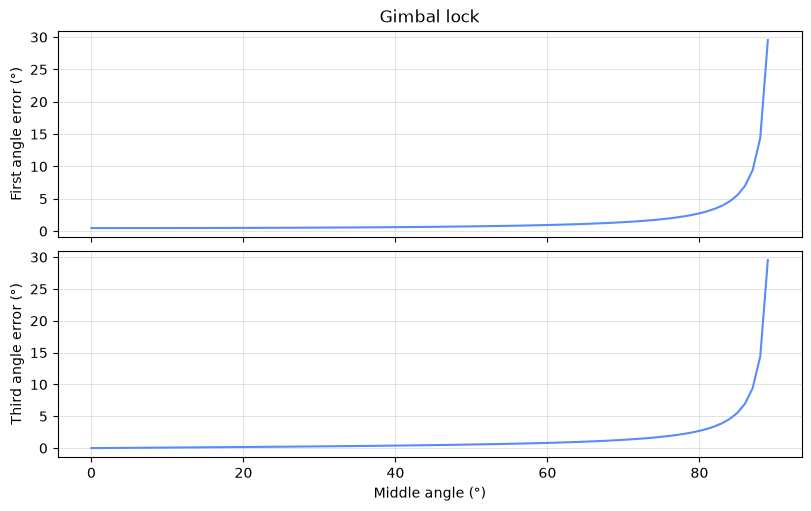

In [34]:
angles = np.array([[30, middle, 20] for middle in range(90)])
nudge = jf.rotation_matrix('X', 0.5)        # a small disturbance of 0.5°
found = jf.cardan_angles(jf.cardan_matrix(angles, 'XYZ') @ nudge, 'XYZ')
error = np.abs(found - angles)[:, [0, 2]]
print(error[[0, 60, 80, 85, 89]].round(1))  # middle angle 0, 60, 80, 85, 89°
jf.plot_curves(angles[:, 1], error, ['First angle error', 'Third angle error'],
               'Gimbal lock', 'figures/gimbal.png', xlabel='Middle angle (°)')

*Error in the first and third Cardan angles (sequence XYZ), caused by a 0.5° disturbance as the middle angle approaches 90°, is plotted above.*

When the middle angle reaches ±90°, the first and third axes line up. Only their sum (or, at −90°, their difference) can be found, and many angle pairs describe one orientation. For example, (30°, 90°, 20°) and (40°, 90°, 10°) describe the same orientation, because both have $a + c = 50°$. When near 90°, the errors are amplified by about 1/cos(middle angle), which grows quickly. The orientation (30°, middle angle, 20°) is disturbed by a turn of only 0.5°, and the angles are found again. The error of the first angle is 0.5° at a middle angle of 0°, 0.9° at 60°, 2.8° at 80°, 5.6° at 85°, and 29.5° at 89°. The third angle behaves the same way (0.0°, 0.8°, 2.7°, 5.5°, 29.5°). With all that considered, gimbal lock is a known weakness of Cardan and Euler angles. The attitude vector avoids gimbal lock and the non-orthogonality problems, and it is less sensitive to measurement errors, but clinicians know it less well ([Woltring, 1994](https://doi.org/10.1016/0021-9290(94)90191-0)). For the knee in the Joint Coordinate System, the middle angle is adduction, which is small, so we stay far from 90° ([Cole et al., 1993](https://doi.org/10.1115/1.2895496)). With flexion in the middle slot, we would not.

### **3. The Joint Coordinate System of Grood and Suntay** ###

The objective of this part is to describe knee motion in clinically meaningful terms, with three rotations ([Grood & Suntay, 1983](https://doi.org/10.1115/1.3138397)). There are three axes: **e1** is fixed in the proximal bone (the femur) and is the flexion–extension axis. **e3** is fixed in the distal bone (the tibia) and is its long axis. The **floating axis e2** is perpendicular to both and is fixed in neither bone ([Grood & Suntay, 1983](https://doi.org/10.1115/1.3138397); [Cole et al., 1993](https://doi.org/10.1115/1.2895496)).

$$\hat e_1=\hat I\ \text{(fixed in the thigh)},\qquad \hat e_3=\hat k\ \text{(fixed in the shank)},\qquad \hat e_2=\frac{\hat e_3\times\hat e_1}{\lVert\hat e_3\times\hat e_1\rVert}\ \text{(floating axis)}$$

In general, e1 and e3 are not perpendicular. The angle between them (β) is 90° only when there is no adduction or abduction. The system is non-orthogonal on purpose, so that each rotation is about an anatomically meaningful axis. The reason why the floating axis matters clinically is that varus–valgus is not measured about a fixed axis. Instead, it is measured about an axis that is perpendicular to the femoral axis and to the tibial axis, so it changes direction as the knee flexes. The three angles are found directly from dot products of the unit vectors of the two segments, with no matrix factorization. For flexion and rotation, atan2 is used so that every quadrant is handled; adduction uses arcsin, which is enough because it always lies between −90° and 90°.

$$\text{Flexion }\alpha:\quad \cos\alpha=\hat J\cdot\hat e_2,\qquad \sin\alpha=-\,\hat e_2\cdot\hat K$$

$$\text{Adduction}:\quad \cos\beta=\hat I\cdot\hat k\ \ (\beta=\text{angle between }\hat e_1\text{ and }\hat e_3),\qquad \text{adduction}=90^\circ-\beta=\arcsin(\hat I\cdot\hat k)$$

$$\text{External rotation }\gamma:\quad \cos\gamma=\hat j\cdot\hat e_2,\qquad \sin\gamma=-\,\hat i\cdot\hat e_2$$

Grood and Suntay chose the signs so that flexion and external rotation are positive for the right knee, and some signs change for the left knee. In this notebook, positive adduction means that the lower end of the shank moves toward the midline (varus). This notebook uses the right leg only. The ISB later adopted the Joint Coordinate System as the base of its standard for other joints, with one axis fixed in each bone ([Wu et al., 2002](https://doi.org/10.1016/S0021-9290(01)00222-6)).

The demo below tests the equations on one known orientation.


In [35]:
print(jf.grood_suntay(np.eye(3)[None], knee_like).round(1))  # thigh = lab

[[60.  5. 10.]]


The thigh axes are set equal to the lab axes, and the shank is the knee-like orientation, built with the Cardan sequence XYZ and the angles (−60°, 5°, −10°). The Grood and Suntay equations return (60°, 5°, 10°). That means the equations are coded correctly, since they give back the angles the orientation was built from. That also means the Grood and Suntay angles are the angles of the Cardan sequence XYZ in the same axes, with the signs of flexion and rotation flipped. So the Joint Coordinate System is a Cardan sequence that turns about the flexion axis first, the floating axis second, and the long axis last. The signs flip because, with *x* to the right, a positive (right-hand) turn about *x* is knee extension, and a positive turn about *z* is internal rotation for a right leg. Grood and Suntay chose flexion and external rotation as positive ([Grood & Suntay, 1983](https://doi.org/10.1115/1.3138397)). But the demo doesn't prove that the segment axes are correct. That depends on the markers and is going to be the subject of Section 4. The ISB describes joints with the axes *x* forward, *y* up, and *z* to the right, which is a different set of axes from the one used here ([Wu et al., 2002](https://doi.org/10.1016/S0021-9290(01)00222-6)). So the real question isn't "which Euler sequence?" The real choices are the axes (how they are defined from landmarks), the order (flexion first, long-axis rotation last), the signs, and the zero position, and all of them must be reported ([Wu et al., 2002](https://doi.org/10.1016/S0021-9290(01)00222-6)). The choice of body-fixed axes has practical consequences: [Cole et al. (1993)](https://doi.org/10.1115/1.2895496) compared the two most common sets and showed that the differences matter in practice.

### **4. Right knee and ankle using sample data** ###

From the openOFM repository, the walking trial recorded with the Vicon system is used, right leg only. The markers used are: pelvis (RASI, LASI, RPSI, LPSI), thigh (RTHI wand and RKNE), shank (RTIB wand and RANK), and foot (RHEE, RTOE, RP5M). In the file, the body measurements can be found: knee width 87 mm, ankle width 69 mm, marker diameter 8 mm.

Step 1: the hip centre is placed from the middle of the two ASIS markers with fixed fractions of the distance between them ([Bell et al., 1990](https://doi.org/10.1016/0021-9290(90)90054-7)). The leg length in the file is only a placeholder, so a leg-length method cannot be used.

($M$ is the middle of the two ASIS markers, $D$ the distance between them; $\hat r$, $\hat f$, $\hat u$ point right, forward, and up from the pelvis):

$$\mathrm{HJC}=M+D\,\bigl(0.36\,\hat r-0.19\,\hat f-0.30\,\hat u\bigr)$$

Step 2: for the knee and ankle centres, the side marker is moved inward by half the joint width plus the marker radius, which is (87 + 8) / 2 = 47.5 mm for the knee and (69 + 8) / 2 = 38.5 mm for the ankle.

($M_{\mathrm{side}}$ is the side marker, $w$ the joint width, $d$ the marker diameter, and $\hat s$ the unit vector pointing out from the long axis toward the side marker):

$$C=M_{\mathrm{side}}-\frac{w+d}{2}\,\hat s$$

Step 3: the segment axes: *z* up the segment, *x* to the right (toward the wand marker), *y* forward. The foot is one plain rigid segment (no foot model): *y* from heel to toe, *z* perpendicular to the plane of heel, toe, and fifth metatarsal head.

($P_{\mathrm{top}}$ is the centre at the upper end, $C$ the centre at the lower end, $W$ the wand marker):

$$\hat z=\frac{P_{\mathrm{top}}-C}{\lVert P_{\mathrm{top}}-C\rVert},\qquad \hat x=\frac{(W-C)-\left[(W-C)\cdot\hat z\right]\hat z}{\lVert\cdots\rVert},\qquad \hat y=\hat z\times\hat x$$

Step 4: the angles: Grood and Suntay for the knee (thigh to shank) and for the ankle (shank to foot).

Step 5: the stance phase is found from marker speed (the foot is on the ground when the heel or the toe moves less than 5 mm per frame, which is 500 mm/s). The threshold is a simple choice, not a published value.

Limits: the axes come from the lateral and wand markers only, with no static calibration trial and no functional method for the knee axis. The flexion axis is therefore approximate, crosstalk is expected, and the zero position is not calibrated, so offsets in the angles are not anatomical ([Ramakrishnan & Kadaba, 1991](https://doi.org/10.1016/0021-9290(91)90175-M); [Piazza & Cavanagh, 2000](https://doi.org/10.1016/S0021-9290(00)00056-7)).

The next demo builds the frames and plots the knee angles.

In [36]:
m, t = jf.load_trial('data/dynamic.c3d')    # m = markers, t = time (s)
hip = jf.hip_centre(m['RASI'], m['LASI'], m['RPSI'], m['LPSI'])
thigh, knee_centre = jf.limb_frame(hip, m['RKNE'], m['RTHI'], 47.5)
shank, _ = jf.limb_frame(knee_centre, m['RANK'], m['RTIB'], 38.5)
foot = jf.foot_frame(m['RHEE'], m['RTOE'], m['RP5M'])
stance = jf.find_stance(m['RHEE'], m['RTOE'])
print('Stance starts or ends at (s):', t[1:][np.diff(stance)])

Stance starts or ends at (s): [0.27 0.95 1.39]


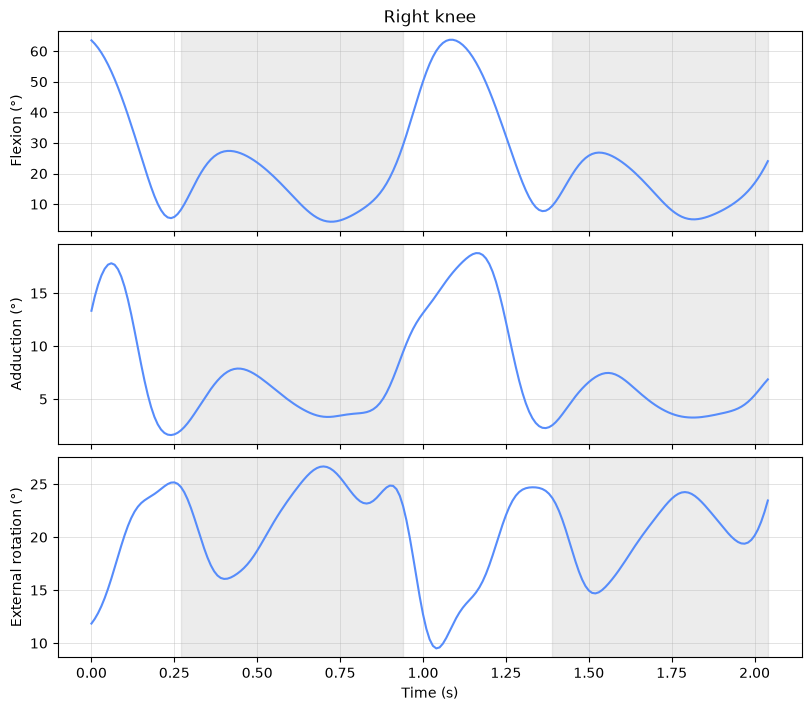

In [37]:
knee = jf.grood_suntay(thigh, shank)
jf.plot_curves(t, knee, ['Flexion', 'Adduction', 'External rotation'],
               'Right knee', 'figures/knee_angles.png', stance)

The grey bands are the times when the right foot is on the ground. Stance starts at 0.27 s (foot contact), swing starts at 0.95 s, and the next foot contact is at 1.39 s. One stride therefore lasts 1.12 s, and the stance phase is about 60 % of it. Flexion has two waves per stride: a small peak of about 27° in early stance and a large peak in swing. Over the trial, it goes from 4.3° to 63.7°. Adduction goes from 1.6° to 18.8°, and rotation from 9.5° to 26.7°. Both stay positive for the whole trial instead of moving around zero, because the neutral position was not calibrated. The adduction curve rises and falls with flexion, and the rotation curve does the opposite; this is examined in the crosstalk test below. Of the three angles, flexion is the one to rely on. It is by far the largest, and the sagittal plane is the most repeatable ([Kadaba et al., 1989](https://doi.org/10.1002/jor.1100070611)). The ankle is analysed the same way in the next cell.

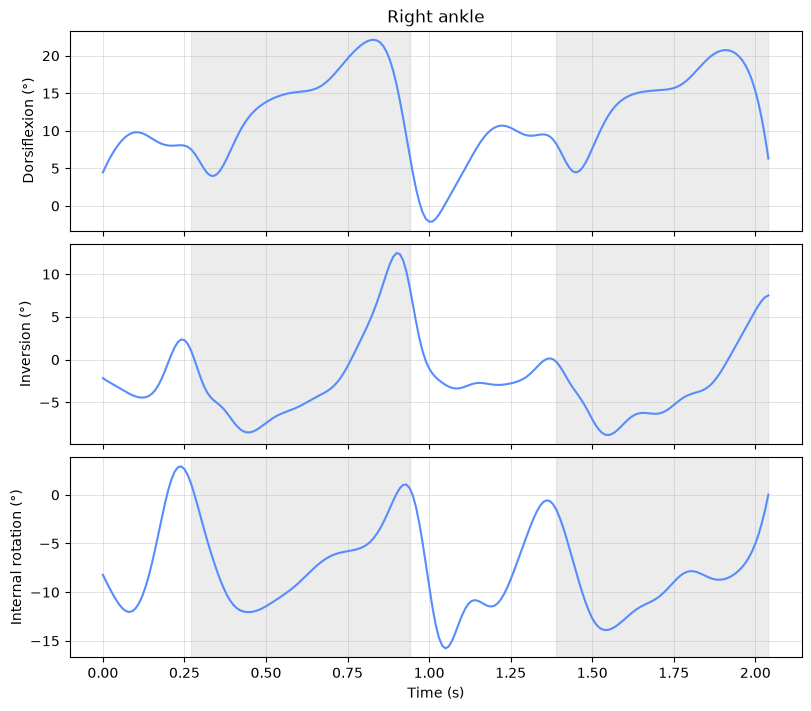

In [38]:
ankle = jf.grood_suntay(shank, foot) * [-1, 1, -1]  # signs: see text below
jf.plot_curves(t, ankle, ['Dorsiflexion', 'Inversion', 'Internal rotation'],
               'Right ankle', 'figures/ankle_angles.png', stance)

With the foot axis pointing up from the sole, the Grood and Suntay flexion of the foot is plantarflexion, so dorsiflexion is its opposite. Adduction of the foot is inversion, and external rotation is the opposite of internal rotation ([Wu et al., 2002](https://doi.org/10.1016/S0021-9290(01)00222-6)). After contact, the foot is lowered, the shank then rotates forward over the foot (dorsiflexion) during stance, the ankle plantarflexes to push off, and it dorsiflexes again in swing. Over the trial, dorsiflexion goes from −2.1° (just after the foot leaves the ground) to 22.1° (late stance). Inversion goes from −8.8° to 12.5°, and internal rotation from −15.8° to 2.9° (negative means the foot points outward). These two angles depend more on the foot axes than dorsiflexion does. Since there is no static calibration, the absolute values should not be compared with normal ranges; the shape and timing of the curves carry the information. The knee also has small out-of-plane angles that look suspicious, and the next cell tests them for crosstalk.

In [39]:
for name, joint in (('Knee', knee), ('Ankle', ankle)):
    print(name, 'min', joint.min(0).round(1), 'max', joint.max(0).round(1),
          'correlation with 1st angle', np.corrcoef(joint.T)[0, 1:].round(2))

Knee min [4.3 1.6 9.5] max [63.7 18.8 26.7] correlation with 1st angle [ 0.96 -0.84]
Ankle min [ -2.1  -8.8 -15.8] max [22.1 12.5  2.9] correlation with 1st angle [0.13 0.06]


#### Checking for crosstalk ####

Crosstalk happens when a misaligned flexion axis makes some of the flexion appear as adduction or rotation ([Piazza & Cavanagh, 2000](https://doi.org/10.1016/S0021-9290(00)00056-7)). So if an out-of-plane curve simply copies flexion, it probably contains crosstalk. The cell prints the smallest and largest value of each angle, and the correlation of the second and third angles with the first one (flexion or dorsiflexion) over the whole trial. For the knee, adduction has a correlation of 0.96 with flexion, and rotation of −0.84. For the ankle, the correlations with dorsiflexion are low (0.13 and 0.06), so the ankle shows no such copying, although its small angles are still uncertain. In theory, an error of 15° in the flexion axis can cause errors of up to 12° in knee adduction and 10–15° in rotation, and the errors depend on the flexion angle ([Ramakrishnan & Kadaba, 1991](https://doi.org/10.1016/0021-9290(91)90175-M)). An important thing to consider is that the real knee couples flexion and rotation (the "screw-home" motion), so a correlation alone cannot separate real coupling from crosstalk. A small axis error can make a pure hinge look like a screw-home ([Piazza & Cavanagh, 2000](https://doi.org/10.1016/S0021-9290(00)00056-7)). The next cell tests what a 10° error in the flexion axis would do.

In [40]:
for tilt in (-10, 0, 10):                   # error of the flexion axis (°)
    tilted = jf.grood_suntay(thigh @ jf.rotation_matrix('Z', tilt), shank)
    print('{:+3d}° tilt, ranges:'.format(tilt), np.ptp(tilted, 0).round(1))

-10° tilt, ranges: [59.9 10.  12.2]
 +0° tilt, ranges: [59.5 17.2 17.2]
+10° tilt, ranges: [58.4 24.6 21.9]


#### What a 10° axis error does ####

The thigh axes are turned by −10°, 0°, and +10° about the long axis of the thigh, which swings the flexion axis backward or forward, as if the axis had been defined slightly wrong. The knee angles are then calculated again from the same markers, and the range (max − min) of each angle is printed. As for the results, the flexion range hardly changes (59.9°, 59.5°, and 58.4°). The adduction range goes from 17.2° to 10.0° or 24.6°, and the rotation range from 17.2° to 12.2° or 21.9°. That means that the small angles depend as much on where the flexion axis is as on the movement itself, while flexion is robust. This agrees in direction with the large errors in adduction and rotation reported for flexion-axis errors of up to 15° ([Ramakrishnan & Kadaba, 1991](https://doi.org/10.1016/0021-9290(91)90175-M); [Piazza & Cavanagh, 2000](https://doi.org/10.1016/S0021-9290(00)00056-7)). Still, this is only a "what if" on the same data: it does not tell us which axis is the true one, and it should not be used to "fix" the curves, because the real knee has some adduction and rotation that a well-chosen tilt would hide. With these limits in mind, the angles can now be read clinically.

### **5. Clinical interpretation** ###

| Joint | Angle | Positive means | Rotation is about |
|:--|:--|:--|:--|
| Knee | Flexion | flexion | $e_1$, fixed in the thigh (to the right) |
| Knee | Adduction | adduction (varus) | $e_2$, the floating axis |
| Knee | Rotation | external rotation | $e_3$, fixed in the shank (long axis) |
| Ankle | Dorsiflexion | dorsiflexion | $e_1$, fixed in the shank (to the right) |
| Ankle | Inversion | inversion | $e_2$, the floating axis |
| Ankle | Internal rotation | internal rotation | $e_3$, fixed in the foot (up from the sole) |

For the knee, the three motions are flexion–extension about e1 (fixed in the thigh), internal–external rotation about e3 (fixed in the shank), and adduction–abduction (varus–valgus) about the floating axis e2 ([Grood & Suntay, 1983](https://doi.org/10.1115/1.3138397)). In this notebook, flexion, adduction (varus), and external rotation are positive. That matters, because the same data would look different with other signs, so they have to be reported in the methods and in the figure captions ([Wu et al., 2002](https://doi.org/10.1016/S0021-9290(01)00222-6)). As for this trial, knee flexion shows two waves per stride: a small one in early stance (about 27°) and a large one in swing (63.7°), with the knee almost straight in late stance (4.3°). This is the angle clinicians look at first, since it is the largest and the most repeatable ([Kadaba et al., 1989](https://doi.org/10.1002/jor.1100070611)). For the ankle, dorsiflexion peaks in late stance (22.1°), the ankle plantarflexes at the start of swing (−2.1°), and it dorsiflexes again in swing (about 10°). Two common problems can be seen directly on this curve; in equinus, the ankle stays in plantarflexion because dorsiflexion is limited, for example by contracted gastrocnemius and soleus muscles. In drop foot, the foot can't be lifted during swing, so there is no heel contact at initial contact; it might be linked to weak or underactive anterior tibial muscles ([Armand et al., 2016](https://doi.org/10.1302/2058-5241.1.000052)). For example, when 10 people with drop foot were compared with 10 controls, the ankle angle in the first 10 % of the gait cycle was −10.4° ± 5.7° versus −2.4° ± 1.5°, they walked about 47 % slower, and the compensation was mostly at the knee and less at the hip ([Wiszomirska et al., 2017](https://doi.org/10.1155/2017/3595461)). That means both problems show up as too little dorsiflexion at contact and in swing. With that said, the angle alone can't tell the cause, so a clinical examination is still needed, since each pattern is linked to different muscle problems ([Armand et al., 2016](https://doi.org/10.1302/2058-5241.1.000052)).

An important thing to consider is that the frontal and transverse angles are small, and they are about the same size as the errors that come with them ([Della Croce et al., 1999](https://doi.org/10.1007/BF02513282)). When landmarks on bones are palpated, the imprecision is 6–21 mm for the same examiner and 13–25 mm between examiners, which can hide movements of 10° or less ([Della Croce et al., 1999](https://doi.org/10.1007/BF02513282)). On top of that, a 15° error in the flexion axis can cause errors of up to 12° in knee adduction and 10–15° in rotation, and those errors change with the flexion angle ([Ramakrishnan & Kadaba, 1991](https://doi.org/10.1016/0021-9290(91)90175-M)). The repeatability follows the same pattern: it is excellent in the sagittal plane, but in the frontal and transverse planes it is good within a day and poor between days, partly because of marker alignment ([Kadaba et al., 1989](https://doi.org/10.1002/jor.1100070611)). This trial shows the same problem. The knee adduction and rotation copy flexion (correlations of 0.96 and −0.84), and tilting the flexion axis by only 10° changes the adduction range from 17.2° to 10.0° or 24.6°. The real knee does couple rotation and extension (the "screw-home" motion), but crosstalk can create the same pattern, so this data can't confirm it ([Piazza & Cavanagh, 2000](https://doi.org/10.1016/S0021-9290(00)00056-7)). With all that considered, the sagittal angles can be trusted, while the other two should be treated as qualitative and only compared within the same subject and the same marker placement.

**<center>References</center>**

Armand, S., Decoulon, G., & Bonnefoy-Mazure, A. (2016). Gait analysis in children with cerebral palsy. *EFORT Open Reviews, 1*, 448–460. https://doi.org/10.1302/2058-5241.1.000052

Bell, A. L., Pedersen, D. R., & Brand, R. A. (1990). A comparison of the accuracy of several hip center location prediction methods. *Journal of Biomechanics, 23*(6), 617–621. https://doi.org/10.1016/0021-9290(90)90054-7

Cole, G. K., Nigg, B. M., Ronsky, J. L., & Yeadon, M. R. (1993). Application of the joint coordinate system to three-dimensional joint attitude and movement representation: A standardization proposal. *Journal of Biomechanical Engineering, 115*(4A), 344–349. https://doi.org/10.1115/1.2895496

Della Croce, U., Cappozzo, A., & Kerrigan, D. C. (1999). Pelvis and lower limb anatomical landmark calibration precision and its propagation to bone geometry and joint angles. *Medical & Biological Engineering & Computing, 37*(2), 155–161. https://doi.org/10.1007/BF02513282

Grood, E. S., & Suntay, W. J. (1983). A joint coordinate system for the clinical description of three-dimensional motions: Application to the knee. *Journal of Biomechanical Engineering, 105*(2), 136–144. https://doi.org/10.1115/1.3138397

Kadaba, M. P., Ramakrishnan, H. K., Wootten, M. E., Gainey, J., Gorton, G., & Cochran, G. V. B. (1989). Repeatability of kinematic, kinetic, and electromyographic data in normal adult gait. *Journal of Orthopaedic Research, 7*(6), 849–860. https://doi.org/10.1002/jor.1100070611

Piazza, S. J., & Cavanagh, P. R. (2000). Measurement of the screw-home motion of the knee is sensitive to errors in axis alignment. *Journal of Biomechanics, 33*(8), 1029–1034. https://doi.org/10.1016/S0021-9290(00)00056-7

Ramakrishnan, H. K., & Kadaba, M. P. (1991). On the estimation of joint kinematics during gait. *Journal of Biomechanics, 24*(10), 969–977. https://doi.org/10.1016/0021-9290(91)90175-M

Wiszomirska, I., Błażkiewicz, M., Kaczmarczyk, K., Brzuszkiewicz-Kuźmicka, G., & Wit, A. (2017). Effect of drop foot on spatiotemporal, kinematic, and kinetic parameters during gait. *Applied Bionics and Biomechanics, 2017*, Article 3595461. https://doi.org/10.1155/2017/3595461

Woltring, H. J. (1994). 3-D attitude representation of human joints: A standardization proposal. *Journal of Biomechanics, 27*(12), 1399–1414. https://doi.org/10.1016/0021-9290(94)90191-0

Wu, G., Siegler, S., Allard, P., Kirtley, C., Leardini, A., Rosenbaum, D., Whittle, M., D'Lima, D. D., Cristofolini, L., Witte, H., Schmid, O., & Stokes, I. (2002). ISB recommendation on definitions of joint coordinate system of various joints for the reporting of human joint motion—Part I: Ankle, hip, and spine. *Journal of Biomechanics, 35*(4), 543–548. https://doi.org/10.1016/S0021-9290(01)00222-6

Prepared by Alexandre Gagnon for EDKP 616 · McGill University · M.Sc. Biomechanics